In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import time

In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xaa.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xab.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xac.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xad.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xae.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xaf.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xag.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xah.dat


In [4]:
import glob

files = sorted(
    glob.glob("/kaggle/input/datasets/badreddineb/vehicle-silhouettes/*.dat")
)

print("Number of files:", len(files))
print("Files:")
for file in files:
    print(file)

Number of files: 8
Files:
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xaa.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xab.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xac.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xad.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xae.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xaf.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xag.dat
/kaggle/input/datasets/badreddineb/vehicle-silhouettes/xah.dat


In [5]:
with open(files[0], "r") as f:
    for i in range(5):
        print(f.readline().strip())

95 48 83 178 72 10 162 42 20 159 176 379 184 70 6 16 187 197 van
91 41 84 141 57 9 149 45 19 143 170 330 158 72 9 14 189 199 van
104 50 106 209 66 10 207 32 23 158 223 635 220 73 14 9 188 196 saab
93 41 82 159 63 9 144 46 19 143 160 309 127 63 6 10 199 207 van
85 44 70 205 103 52 149 45 19 144 241 325 188 127 9 11 180 183 bus


In [6]:
# Read all data files and combine them

data = []

for file in files:
    with open(file, "r") as f:
        for line in f:
            values = line.strip().split()
            data.append(values)

columns = [
    "COMPACTNESS",
    "CIRCULARITY",
    "DISTANCE_CIRCULARITY",
    "RADIUS_RATIO",
    "PR_AXIS_ASPECT_RATIO",
    "MAX_LENGTH_ASPECT_RATIO",
    "SCATTER_RATIO",
    "ELONGATEDNESS",
    "PR_AXIS_RECTANGULARITY",
    "MAX_LENGTH_RECTANGULARITY",
    "SCALED_VARIANCE_MAJOR",
    "SCALED_VARIANCE_MINOR",
    "SCALED_RADIUS_OF_GYRATION",
    "SKEWNESS_ABOUT_MAJOR",
    "SKEWNESS_ABOUT_MINOR",
    "KURTOSIS_ABOUT_MAJOR",
    "KURTOSIS_ABOUT_MINOR",
    "HOLLOWS_RATIO",
    "class"
]

df = pd.DataFrame(data, columns=columns)

# Convert feature columns to numeric
feature_columns = columns[:-1]
df[feature_columns] = df[feature_columns].astype(float)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully
Dataset shape: (752, 19)


,COMPACTNESS,CIRCULARITY,DISTANCE_CIRCULARITY,RADIUS_RATIO,PR_AXIS_ASPECT_RATIO,MAX_LENGTH_ASPECT_RATIO,SCATTER_RATIO,ELONGATEDNESS,PR_AXIS_RECTANGULARITY,MAX_LENGTH_RECTANGULARITY,SCALED_VARIANCE_MAJOR,SCALED_VARIANCE_MINOR,SCALED_RADIUS_OF_GYRATION,SKEWNESS_ABOUT_MAJOR,SKEWNESS_ABOUT_MINOR,KURTOSIS_ABOUT_MAJOR,KURTOSIS_ABOUT_MINOR,HOLLOWS_RATIO,class
0,95.0,48.0,83.0,178.0,72.0,10.0,162.0,42.0,20.0,159.0,176.0,379.0,184.0,70.0,6.0,16.0,187.0,197.0,van
1,91.0,41.0,84.0,141.0,57.0,9.0,149.0,45.0,19.0,143.0,170.0,330.0,158.0,72.0,9.0,14.0,189.0,199.0,van
2,104.0,50.0,106.0,209.0,66.0,10.0,207.0,32.0,23.0,158.0,223.0,635.0,220.0,73.0,14.0,9.0,188.0,196.0,saab
3,93.0,41.0,82.0,159.0,63.0,9.0,144.0,46.0,19.0,143.0,160.0,309.0,127.0,63.0,6.0,10.0,199.0,207.0,van
4,85.0,44.0,70.0,205.0,103.0,52.0,149.0,45.0,19.0,144.0,241.0,325.0,188.0,127.0,9.0,11.0,180.0,183.0,bus


In [7]:
# Define features and target

X = df.drop(columns=["class"])
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique()))

print("\nNumber of classes:", y.nunique())

print("\nClass distribution:")
print(y.value_counts())

Features shape: (752, 18)
Target shape: (752,)

Target classes:
['bus', 'opel', 'saab', 'van']

Number of classes: 4

Class distribution:
class
bus     196
opel    190
saab    189
van     177
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set shape: (601, 18)
Testing set shape: (151, 18)

Training class distribution:
class
bus     157
opel    152
saab    151
van     141
Name: count, dtype: int64

Testing class distribution:
class
bus     39
saab    38
opel    38
van     36
Name: count, dtype: int64


In [9]:
# Create the Random Forest Baseline model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Random Forest Baseline trained successfully")
print(f"Training time: {training_time:.4f} seconds")

Random Forest Baseline trained successfully
Training time: 0.3059 seconds


In [10]:
# Make predictions on the test set

y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Random Forest Baseline Results")
print("------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Random Forest Baseline Results
------------------------------
Accuracy : 0.7550
Precision: 0.7463
Recall   : 0.7550
F1-Score : 0.7501


Confusion Matrix:
[[39  0  0  0]
 [ 0 21 14  3]
 [ 2 13 21  2]
 [ 0  2  1 33]]


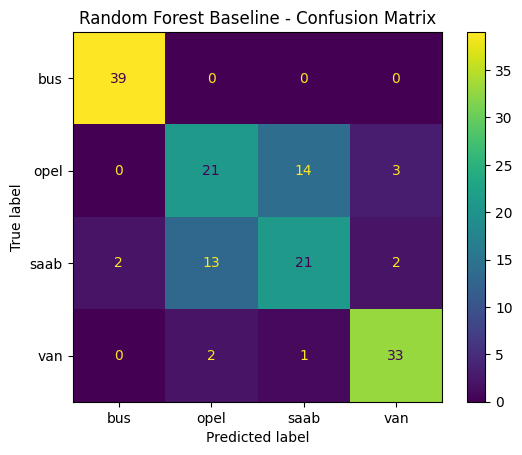

In [11]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(y_test.unique())
)

disp.plot()

plt.title("Random Forest Baseline - Confusion Matrix")
plt.show()

Feature Importance:


,Importance
MAX_LENGTH_ASPECT_RATIO,0.115896
SCALED_VARIANCE_MINOR,0.076309
SCALED_VARIANCE_MAJOR,0.068735
DISTANCE_CIRCULARITY,0.067969
ELONGATEDNESS,0.066283
MAX_LENGTH_RECTANGULARITY,0.066199
SCATTER_RATIO,0.062082
PR_AXIS_ASPECT_RATIO,0.059677
COMPACTNESS,0.056490
HOLLOWS_RATIO,0.051338


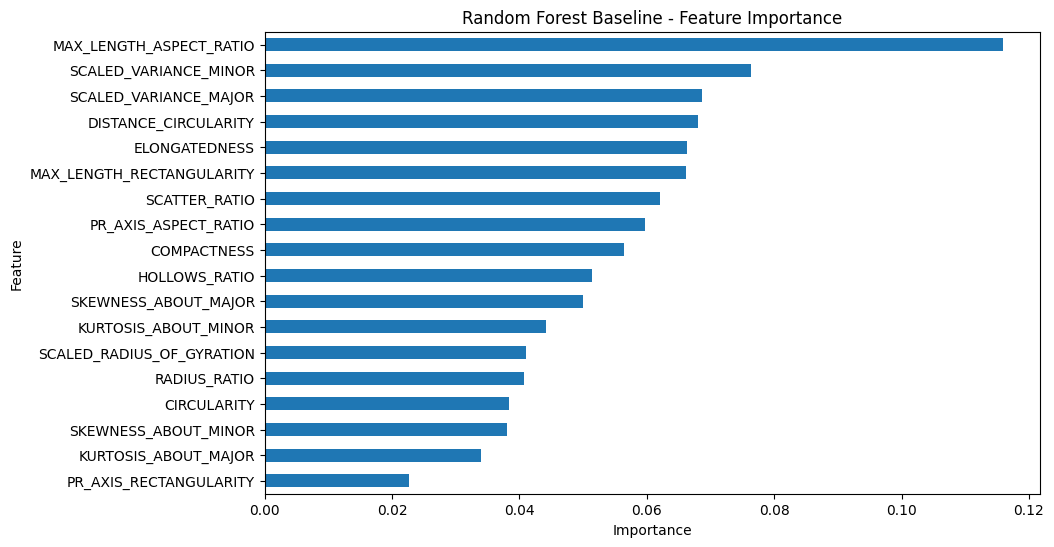

In [12]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
display(feature_importance.to_frame(name="Importance"))

plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.title("Random Forest Baseline - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [13]:
baseline_results = {
    "Model": "Random Forest Baseline",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Training Time": training_time
}

results_df = pd.DataFrame([baseline_results])

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,Training Time
0,Random Forest Baseline,0.754967,0.746318,0.754967,0.750121,0.305943
